# Wireless Networking and Mobile Computing

### Prerequisites

This Jupyter Notebook has been tested with Visual Studio Code, running in a local Python environment.

**Installs**

In [1]:
# --- Installs: ensure required packages are available ---
%pip install matplotlib pandas --quiet

Note: you may need to restart the kernel to use updated packages.


**Imports**

In [2]:
# --- Imports: libraries used in this notebook ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

### 1. MIMO (Multiple Input, Multiple Output)

#### 1.1 Multipath and MIMO

In single-antenna systems, multipath propagation causes interference and fading. Reflections arrive with different delays and phases, distorting the received signal.

However, MIMO (Multiple Input, Multiple Output) systems use this same multipath environment to their advantage. Each transmit antenna and each receive antenna pair experiences a slightly different version of the channel. These distinct paths can carry independent information if properly separated, effectively turning one physical channel into multiple *parallel spatial channels*.

Modern wireless systems (Wi-Fi 6/7, 4G LTE, 5G) rely heavily on this concept.

### 1.2 Overview
In practical MIMO systems, signals from different antennas are rarely fully independent. While spatial multiplexing allows multiple data streams to be transmitted simultaneously, the shared radio channel causes coupling between them. This interaction can be mitigated or even exploited through smart design.

- **Spatial Multiplexing**: Each antenna can transmit a separate data stream, but all travel through the same medium, causing interference. The receiver must separate these overlapping signals using techniques like channel estimation or equalization.
- **Precoding and Correlation**: Transmit signals are often intentionally correlated using *precoding*, a method that shapes and weights them based on channel knowledge. This helps reduce interference and improve overall link quality.

- **Diversity and Beamforming**: Instead of sending different data, antennas can transmit the same information with slight variations (phase or timing) to improve reliability. This is *diversity*. In *beamforming*, signals are aligned in phase to focus energy toward the receiver, boosting performance.

- **Channel and Coding Effects**: Even with independent streams, the channel itself mixes the signals. Error correction and coding then help recover the data, sometimes adding controlled correlation for robustness.


### 1.3 Matrix Representation
A very basic mathematical model for MIMO can be described using matrix notation. Assume we have $ N_t $ transmit antennas and $ N_r $ receive antennas. The system can be represented by a channel matrix $ \mathbf{H} $, which models the effect of the wireless channel between each transmit antenna and each receive antenna.

Let $ \mathbf{x} $ be the $ N_t \times 1 $ vector representing the transmitted signals. Each element of $ \mathbf{x} $ represents the signal transmitted from each antenna. 

Let $ \mathbf{y} $ be the $ N_r \times 1 $ vector representing the received signals at the receiver. The channel between the transmit and receive antennas is represented by a channel matrix $ \mathbf{H} $ of size $ N_r \times N_t $. Each element $ h_{ij} $ of $ \mathbf{H} $ represents the gain (amplitude and phase change) of the wireless channel from the $ j $-th transmit antenna to the $ i $-th receive antenna. 

Additionally, noise is present in the system, modeled by an $ N_r \times 1 $ noise vector $ \mathbf{n} $, which is typically assumed to be Gaussian with mean zero and some variance.

#### 1.4 MIMO Model Equation
   The basic MIMO system can be modeled as:

   $
   \mathbf{y} = \mathbf{H} \mathbf{x} + \mathbf{n},
   $
   
   where
   - $ \mathbf{y} $ is the $ N_r \times 1 $ vector of received signals.
   - $ \mathbf{H} $ is the $ N_r \times N_t $ channel matrix.
   - $ \mathbf{x} $ is the $ N_t \times 1 $ vector of transmitted signals.
   - $ \mathbf{n} $ is the $ N_r \times 1 $ noise vector.

#### 1.5 Components Breakdown
   - Transmit Signal ($ \mathbf{x} $)  
   
     $
     \mathbf{x} = 
     \begin{bmatrix}
     x_1 \\
     x_2 \\
     \vdots \\
     x_{N_t}
     \end{bmatrix}
     $

     Here, $ x_1, x_2, \dots, x_{N_t} $ are the signals sent from each transmit antenna.
   
   - Channel Matrix ($ \mathbf{H} $) 

     $
     \mathbf{H} = 
     \begin{bmatrix}
     h_{11} & h_{12} & \dots & h_{1N_t} \\
     h_{21} & h_{22} & \dots & h_{2N_t} \\
     \vdots & \vdots & \ddots & \vdots \\
     h_{N_r1} & h_{N_r2} & \dots & h_{N_r N_t}
     \end{bmatrix}
     $

     The matrix $ \mathbf{H} $ captures the relationship between each transmit and receive antenna. Each element $ h_{ij} $ represents the channel gain from the $ j $-th transmit antenna to the $ i $-th receive antenna.
   
   - Received Signal ($ \mathbf{y} $) 

     $
     \mathbf{y} = 
     \begin{bmatrix}
     y_1 \\
     y_2 \\
     \vdots \\
     y_{N_r}
     \end{bmatrix}
     $
   
     In this term, $ y_1, y_2, \dots, y_{N_r} $ are the received signals at each receive antenna.
   
   - Noise Vector ($ \mathbf{n} $)  
   
     $
     \mathbf{n} = 
     \begin{bmatrix}
     n_1 \\
     n_2 \\
     \vdots \\
     n_{N_r}
     \end{bmatrix}
     $
   
     Here, $ n_1, n_2, \dots, n_{N_r} $ are independent noise terms, typically modeled as additive white Gaussian noise (AWGN).

#### 1.6 Example Visualization

Channel Matrix H:
  [-0.417  -0.056]
  [-2.136   1.640]

Transmit Vector x:
  [ 1.000]
  [ 0.500]

Received Vector y:
  [-0.624]
  [-1.400]



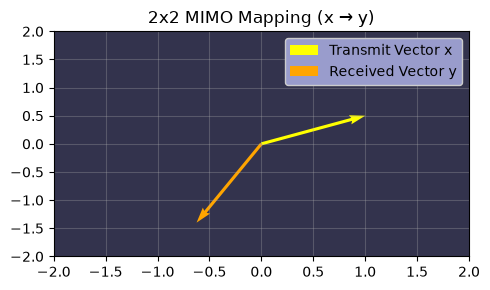

In [3]:
# --- Visualization: Simple 2x2 MIMO mapping ---
np.random.seed(2)
H = np.random.randn(2, 2)  # Channel matrix
x = np.array([[1], [0.5]])  # Transmit signals
n = np.random.normal(0, 0.1, (2, 1))  # AWGN noise
y = H @ x + n  # Received signals

def print_matrix(name, M):
    print(f"{name}:")
    for row in M:
        print("  [" + "  ".join(f"{v:6.3f}" for v in row) + "]")
    print()

print_matrix("Channel Matrix H", H)
print_matrix("Transmit Vector x", x)
print_matrix("Received Vector y", y)

fig, ax = plt.subplots(figsize=(5, 3))
ax.quiver(0, 0, x[0], x[1], angles='xy', scale_units='xy', scale=1, color='yellow', label='Transmit Vector x')
ax.quiver(0, 0, y[0], y[1], angles='xy', scale_units='xy', scale=1, color='orange', label='Received Vector y')

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_facecolor((0.2, 0.2, 0.3))
ax.grid(True, alpha=0.3)
ax.legend(fancybox=True, framealpha=1, facecolor=(0.6, 0.61, 0.8))
ax.set_title("2x2 MIMO Mapping (x → y)")
plt.tight_layout()
plt.show()


### 2. Interpretation
   The matrix equation $ \mathbf{y} = \mathbf{H} \mathbf{x} + \mathbf{n} $ means that the received signal $ \mathbf{y} $ is the result of multiplying the transmitted signal vector $ \mathbf{x} $ by the channel matrix $ \mathbf{H} $, which models how the signals from different transmit antennas combine at the receive antennas, plus the noise vector $ \mathbf{n} $.

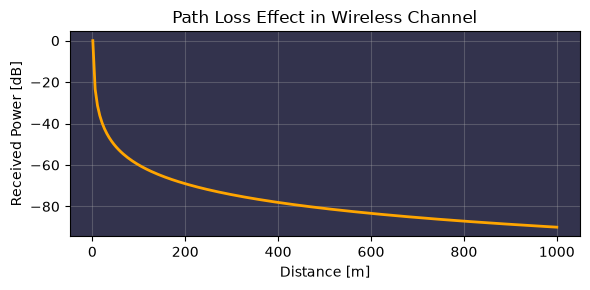

In [4]:
# --- Visualization: Received power vs. distance ---
Pt = 1  # Transmit power (W)
distances = np.linspace(1, 1000, 200)  # meters
path_loss_exp = 3  # Path loss exponent (urban)
Pr = Pt / (distances ** path_loss_exp)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(distances, 10 * np.log10(Pr / Pt), lw=2, color='orange')
ax.set_xlabel("Distance [m]")
ax.set_ylabel("Received Power [dB]")
ax.set_title("Path Loss Effect in Wireless Channel")
ax.set_facecolor((0.2, 0.2, 0.3))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3. Solving for the Transmitted Signal
   In a simple case (ignoring noise and assuming $ \mathbf{H} $ is invertible), the receiver could recover the transmitted signal $ \mathbf{x} $ by inverting the channel matrix $ \mathbf{H} $:
 
   $
   \mathbf{x} = \mathbf{H}^{-1} \mathbf{y}
   $
 
   In reality, noise and channel imperfections make this more complicated, and advanced techniques like Zero Forcing (ZF) or Minimum Mean Square Error (MMSE) are used to estimate $ \mathbf{x} $ from $ \mathbf{y} $. As example, assume we have a $ 2 \times 2 $ MIMO system, with 2 transmit and 2 receive antennas. The model would look like this:
   
   $
   \mathbf{y} = 
   \begin{bmatrix}
   y_1 \\
   y_2
   \end{bmatrix} =
   \begin{bmatrix}
   h_{11} & h_{12} \\
   h_{21} & h_{22}
   \end{bmatrix}
   \begin{bmatrix}
   x_1 \\
   x_2
   \end{bmatrix}
   +
   \begin{bmatrix}
   n_1 \\
   n_2
   \end{bmatrix}
   $
   
   In practice, additional factors like error correction, channel estimation, and coding further enhance the performance of MIMO systems.

True x (Transmit):
  [-0.277]
  [-0.355]

Received y (Distorted):
  [-0.659]
  [ 0.572]

Estimated x̂ (Recovered):
  [-0.290]
  [-0.322]

Estimation Error: 0.035


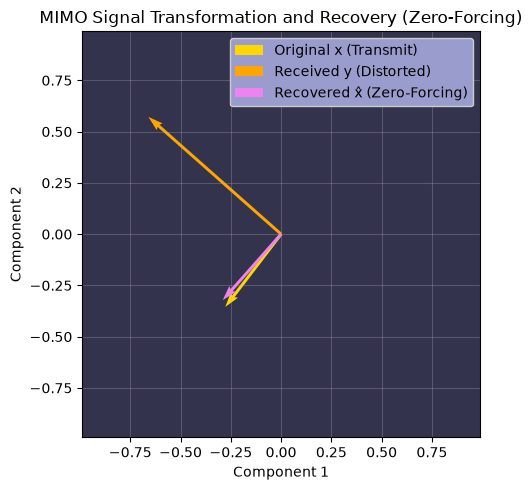

In [5]:
# --- Demonstration: Zero-Forcing Equalization (with consistent visualization) ---
np.random.seed(3)
H = np.random.randn(2, 2)
x_true = np.random.randn(2, 1)
n = np.random.normal(0, 0.1, (2, 1))
y = H @ x_true + n

x_est = np.linalg.inv(H) @ y
error = np.linalg.norm(x_est - x_true)

print_matrix("True x (Transmit)", x_true)
print_matrix("Received y (Distorted)", y)
print_matrix("Estimated x̂ (Recovered)", x_est)

print(f"Estimation Error: {error:.3f}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(5, 5))
ax.quiver(0, 0, x_true[0], x_true[1], angles='xy', scale_units='xy', scale=1, 
          color='gold', label='Original x (Transmit)', linewidth=2)
ax.quiver(0, 0, y[0], y[1], angles='xy', scale_units='xy', scale=1, 
          color='orange', label='Received y (Distorted)', linewidth=2)
ax.quiver(0, 0, x_est[0], x_est[1], angles='xy', scale_units='xy', scale=1, 
          color='violet', label='Recovered x̂ (Zero-Forcing)', linewidth=2)

# Set plot limits dynamically for better scaling
limit = 1.5 * np.max(np.abs([x_true, y, x_est]))
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
ax.set_title("MIMO Signal Transformation and Recovery (Zero-Forcing)")
ax.grid(True, alpha=0.3)
ax.set_facecolor((0.2, 0.2, 0.3))
ax.legend(fancybox=True, framealpha=1, facecolor=(0.6, 0.61, 0.8))
plt.tight_layout()
plt.show()